# Default of Credit Card Clients

**Задача:** оценить вероятность невыполнения платежного обязательства по кредитной карте в следующем месяце по данным о клиенте и его предыдущих платежах.

**Источник:** [UCI Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), исходный `default of credit card clients.xls`. Файл лежит рядом с ноутбуком. Библиотеки: `pandas`, `matplotlib`, `seaborn`, `xlrd`.


## 1. Таблица

Размер, типы, первые строки и основные статистики по всем столбцам.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_excel("default of credit card clients.xls", sheet_name="Data", header=1, engine="xlrd")
target = "default payment next month"
print("Размер:", df.shape)
display(df.head())

C:\Users\PC\AppData\Local\Temp\ipykernel_8476\4281533701.py:7: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel("default of credit card clients.xls", sheet_name="Data", header=1, engine="xlrd")


Размер: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [2]:
display(df.describe(include="all").T.round(2))
print("Входных признаков:", df.shape[1] - 2)
print("Числовых входных:", df.drop(columns=["ID", target]).select_dtypes("number").shape[1])

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.50,8660.40,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0


Входных признаков: 23
Числовых входных: 23


В таблице 30 000 строк и 25 столбцов: `ID`, 23 входных признака и `default payment next month`. Все столбцы прочитаны как числовые. `SEX`, `EDUCATION`, `MARRIAGE` и статусы `PAY_*` содержат коды категорий.

## 2. Таргет

Распределение исходов и доля положительного класса.

default payment next month
0    23364
1     6636
Name: count, dtype: int64
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


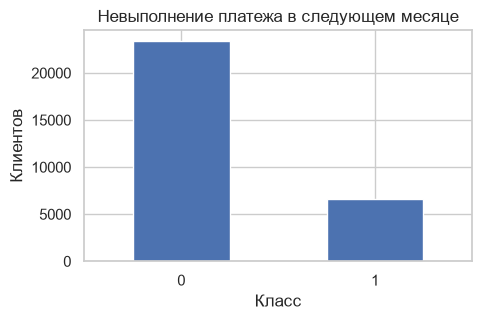

In [3]:
print(df[target].value_counts().sort_index())
print((df[target].value_counts(normalize=True).sort_index() * 100).round(2))
df[target].value_counts().sort_index().plot.bar(figsize=(5, 3), rot=0)
plt.title("Невыполнение платежа в следующем месяце")
plt.xlabel("Класс")
plt.ylabel("Клиентов")
plt.show()

`0` - 23 364 клиента (77,88%), `1` - 6 636 (22,12%). Постоянный прогноз `0` дал бы accuracy 77,88%, не выявляя клиентов с невыполнением платежа.

## 3. Пропуски и дубликаты

Проверка отсутствующих значений, идентификаторов и совпадающих наборов признаков.

In [4]:
missing = pd.DataFrame({"NaN": df.isna().sum(), "NaN, %": (df.isna().mean() * 100).round(2)})
display(missing)
print("Всего NaN:", int(df.isna().sum().sum()))
print("Полные дубликаты:", int(df.duplicated().sum()))
print("Повторы ID:", int(df["ID"].duplicated().sum()))
print("Повторы строк без ID (с таргетом):", int(df.drop(columns="ID").duplicated().sum()))
inputs = df.drop(columns=["ID", target])
print("Повторы входных признаков:", int(inputs.duplicated().sum()))
print("Группы совпадающих признаков с разным таргетом:",
      int(df.groupby(inputs.columns.tolist())[target].nunique().gt(1).sum()))

,NaN,"NaN, %"
ID,0,0.0
LIMIT_BAL,0,0.0
SEX,0,0.0
EDUCATION,0,0.0
MARRIAGE,0,0.0
AGE,0,0.0
PAY_0,0,0.0
PAY_2,0,0.0
PAY_3,0,0.0
PAY_4,0,0.0


Всего NaN: 0
Полные дубликаты: 0
Повторы ID: 0
Повторы строк без ID (с таргетом): 35
Повторы входных признаков: 56
Группы совпадающих признаков с разным таргетом: 21


Формальных `NaN`, полных дубликатов и повторов `ID` нет. Повторов строк без `ID` (но с таргетом) - 35. Повторов только входных признаков - 56. В 21 группе одинаковых признаков таргет различается. Совпадение признаков не устанавливает, что записи относятся к одному клиенту.

## 4. Коды и диапазоны

Проверка категориальных кодов, отрицательных и нулевых финансовых величин.

In [5]:
print("AGE: минимум / медиана / максимум:", df["AGE"].min(), df["AGE"].median(), df["AGE"].max())
print("LIMIT_BAL: минимум / медиана / максимум:", df["LIMIT_BAL"].min(), df["LIMIT_BAL"].median(), df["LIMIT_BAL"].max())
print("EDUCATION 0/5/6:", int(df["EDUCATION"].isin([0, 5, 6]).sum()))
print("MARRIAGE = 0:", int(df["MARRIAGE"].eq(0).sum()))
print("BILL_AMT1 < 0:", int(df["BILL_AMT1"].lt(0).sum()))
print("PAY_AMT1 = 0:", int(df["PAY_AMT1"].eq(0).sum()))
print("PAY_AMT1 < 0:", int(df["PAY_AMT1"].lt(0).sum()))

AGE: минимум / медиана / максимум: 21 34.0 79
LIMIT_BAL: минимум / медиана / максимум: 10000 140000.0 1000000
EDUCATION 0/5/6: 345
MARRIAGE = 0: 54
BILL_AMT1 < 0: 590
PAY_AMT1 = 0: 5249
PAY_AMT1 < 0: 0


In [6]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
status = pd.DataFrame({"-2": [df[c].eq(-2).sum() for c in pay_cols],
                       "-1": [df[c].eq(-1).sum() for c in pay_cols],
                       "0": [df[c].eq(0).sum() for c in pay_cols],
                       ">0": [df[c].gt(0).sum() for c in pay_cols]}, index=pay_cols)
display(status)
print("Коды EDUCATION:", sorted(df["EDUCATION"].unique()))
print("Коды MARRIAGE:", sorted(df["MARRIAGE"].unique()))

,-2,-1,0,>0
PAY_0,2759,5686,14737,6818
PAY_2,3782,6050,15730,4438
PAY_3,4085,5938,15764,4213
PAY_4,4348,5687,16455,3510
PAY_5,4546,5539,16947,2968
PAY_6,4895,5740,16286,3079


Коды EDUCATION: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Коды MARRIAGE: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


Возраст - от 21 до 79 лет, кредитный лимит - от 10 000 до 1 000 000 новых тайваньских долларов. `EDUCATION` содержит 345 записей с кодами `0`, `5`, `6`; `MARRIAGE = 0` - 54 записи. Эти коды не раскрыты в базовом описании UCI. Во всех шести `PAY_*` встречаются `-2` и `0`, которые не объясняются приведённой в UCI шкалой. Отрицательные `BILL_AMT1` встречаются 590 раз, нулевые `PAY_AMT1` - 5 249 раз.

## 5. Числовые распределения и выбросы

Гистограммы 14 количественных признаков: лимит, возраст, суммы счетов и платежей. IQR применяется к возрасту, лимиту и сумме счёта, но не к кодам статусов платежей.

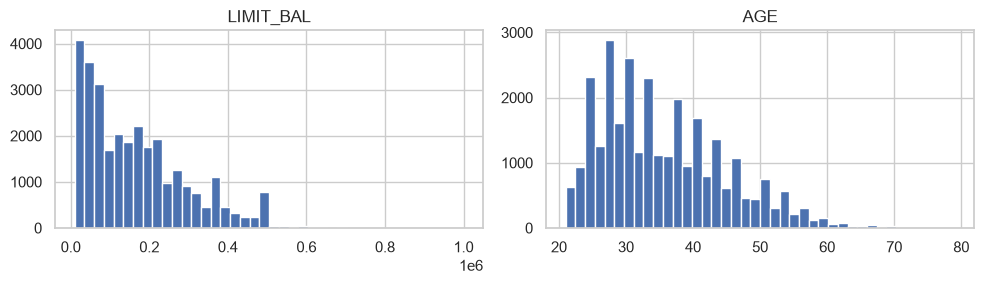

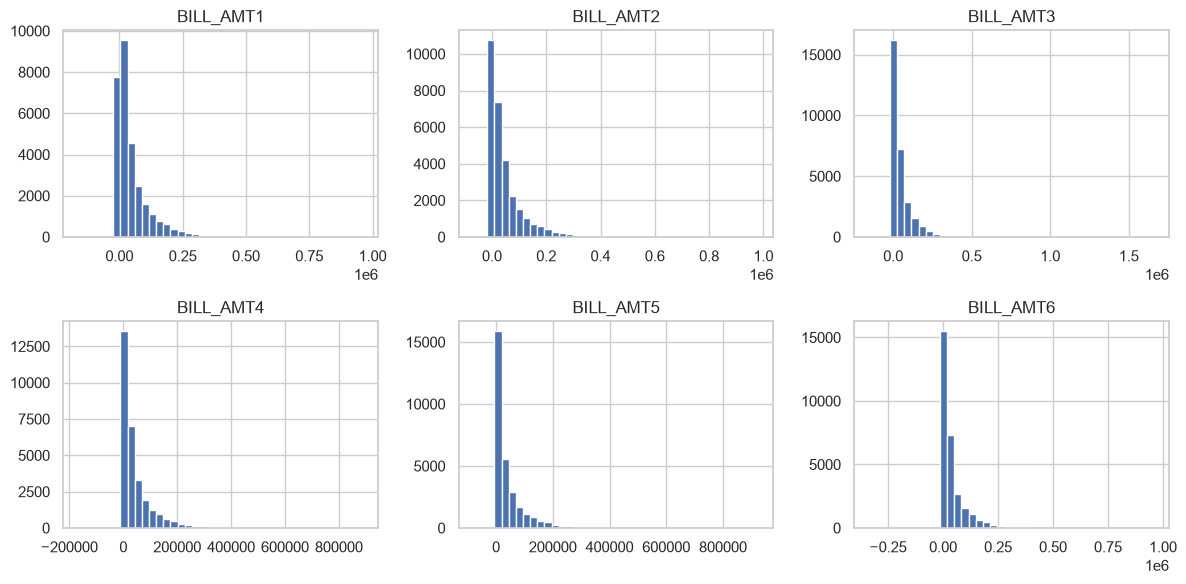

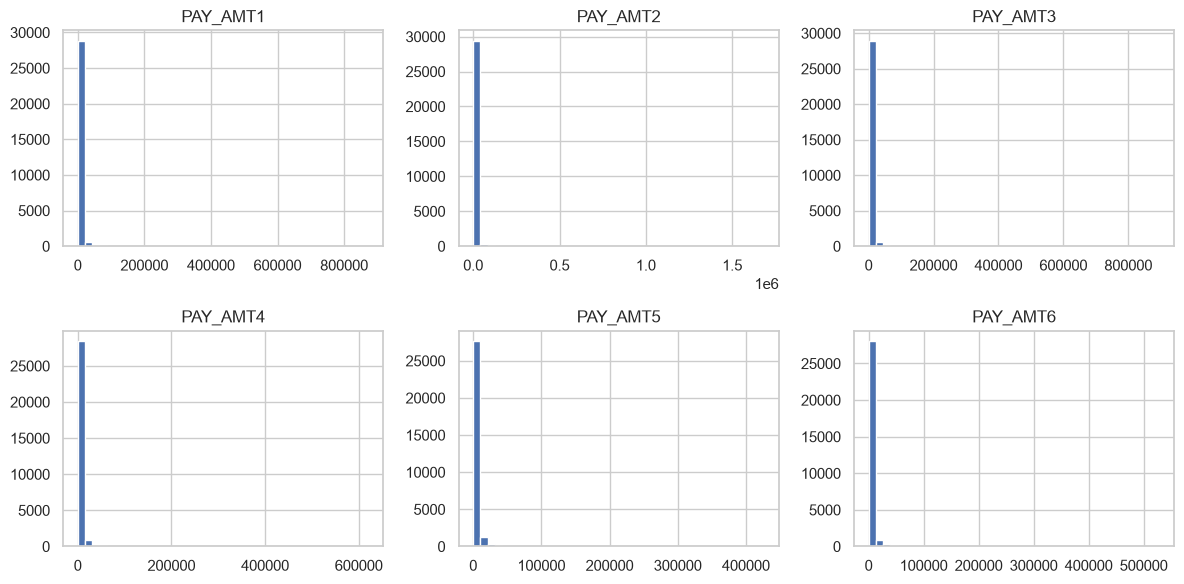

In [7]:
df[["LIMIT_BAL", "AGE"]].hist(bins=40, figsize=(10, 3))
plt.tight_layout()
plt.show()

bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amount_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
df[bill_cols].hist(bins=40, figsize=(12, 6), layout=(2, 3))
plt.tight_layout()
plt.show()
df[pay_amount_cols].hist(bins=40, figsize=(12, 6), layout=(2, 3))
plt.tight_layout()
plt.show()

In [8]:
for col in ["AGE", "LIMIT_BAL", "BILL_AMT1"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    outside = df[col].lt(q1 - 1.5 * (q3-q1)) | df[col].gt(q3 + 1.5 * (q3-q1))
    print(col, "медиана:", df[col].median(), "IQR:", int(outside.sum()),
          "доля, %:", round(100 * outside.mean(), 2))

AGE медиана: 34.0 IQR: 272 доля, %: 0.91
LIMIT_BAL медиана: 140000.0 IQR: 167 доля, %: 0.56
BILL_AMT1 медиана: 22381.5 IQR: 2400 доля, %: 8.0


По правилу 1,5 IQR получено 272 сигнала для `AGE` (0,91%), 167 для `LIMIT_BAL` (0,56%) и 2 400 для `BILL_AMT1` (8,00%). Большие лимиты и суммы счетов не считаются ошибками только на основании IQR.

## 6. Категориальные признаки и связь с таргетом

Количество клиентов и доля `1` для кодов категорий, включая историю задержек.

In [9]:
for col in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0"]:
    tab = df.groupby(col)[target].agg(["size", "mean"])
    tab["mean"] = (100 * tab["mean"]).round(2)
    print("\n", col, "- количество / доля 1, %")
    display(tab.rename(columns={"size":"Клиентов", "mean":"1, %"}))


 SEX - количество / доля 1, %


,Клиентов,"1, %"
SEX,,
1,11888,24.17
2,18112,20.78



 EDUCATION - количество / доля 1, %


,Клиентов,"1, %"
EDUCATION,,
0,14,0.00
1,10585,19.23
2,14030,23.73
3,4917,25.16
4,123,5.69
5,280,6.43
6,51,15.69



 MARRIAGE - количество / доля 1, %


,Клиентов,"1, %"
MARRIAGE,,
0,54,9.26
1,13659,23.47
2,15964,20.93
3,323,26.01



 PAY_0 - количество / доля 1, %


,Клиентов,"1, %"
PAY_0,,
-2,2759,13.23
-1,5686,16.78
0,14737,12.81
1,3688,33.95
2,2667,69.14
3,322,75.78
4,76,68.42
5,26,50.00
6,11,54.55


In [10]:
for col in ["PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    tab = df.groupby(col)[target].agg(["size", "mean"])
    tab["mean"] = (100 * tab["mean"]).round(2)
    print("\n", col)
    display(tab.rename(columns={"size":"Клиентов", "mean":"1, %"}))


 PAY_2


,Клиентов,"1, %"
PAY_2,,
-2,3782,18.27
-1,6050,15.97
0,15730,15.91
1,28,17.86
2,3927,55.61
3,326,61.66
4,99,50.51
5,25,60.00
6,12,75.00



 PAY_3


,Клиентов,"1, %"
PAY_3,,
-2,4085,18.53
-1,5938,15.59
0,15764,17.45
1,4,25.00
2,3819,51.56
3,240,57.50
4,76,57.89
5,21,57.14
6,23,60.87



 PAY_4


,Клиентов,"1, %"
PAY_4,,
-2,4348,19.25
-1,5687,15.90
0,16455,18.33
1,2,50.00
2,3159,52.33
3,180,61.11
4,69,66.67
5,35,51.43
6,5,40.00



 PAY_5


,Клиентов,"1, %"
PAY_5,,
-2,4546,19.69
-1,5539,16.19
0,16947,18.85
2,2626,54.19
3,178,63.48
4,84,60.71
5,17,58.82
6,4,75.00
7,58,82.76



 PAY_6


,Клиентов,"1, %"
PAY_6,,
-2,4895,20.04
-1,5740,16.99
0,16286,18.84
2,2766,50.65
3,184,64.13
4,49,63.27
5,13,53.85
6,19,73.68
7,46,82.61


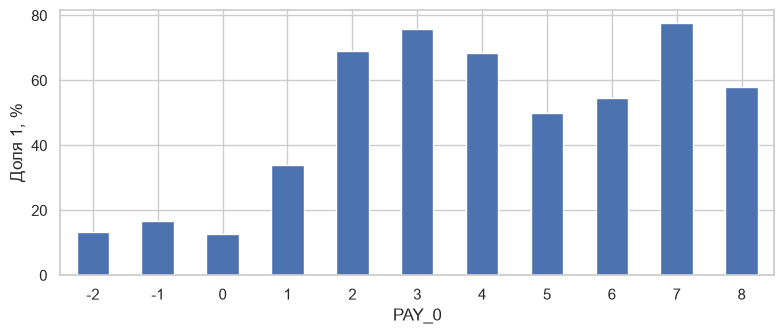

In [11]:
pay0 = df.groupby("PAY_0")[target].agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(8, 3.5))
(pay0["mean"] * 100).plot.bar(ax=ax, rot=0)
ax.set_ylabel("Доля 1, %")
ax.set_xlabel("PAY_0")
plt.tight_layout()
plt.show()

Для `PAY_0 = 0` доля `1` - 12,81% (14 737 клиентов); при `PAY_0 = 1` - 33,95% (3 688), при `PAY_0 = 2` - 69,14% (2 667). В группах с редкими кодами размер выборки мал. Для `SEX = 1` доля `1` составляет 24,17%, для `SEX = 2` - 20,78%. Эти различия не устанавливают причинную связь.

## 7. Числовые признаки и корреляции

Медианы финансовых показателей по классам и корреляции количественных признаков. Категориальные коды `SEX`, `EDUCATION`, `MARRIAGE` и `PAY_*` не включаются в расчёт Pearson.

In [12]:
amount_cols = ["LIMIT_BAL", "AGE"] + bill_cols + pay_amount_cols
display(df.groupby(target)[amount_cols].median().T)
corr_target = df[amount_cols + [target]].corr()[target].drop(target)
print("Корреляции количественных признаков с таргетом:")
print(corr_target.round(3).sort_values(ascending=False).to_string())

default payment next month,0,1
LIMIT_BAL,150000.0,90000.0
AGE,34.0,34.0
BILL_AMT1,23119.5,20185.0
BILL_AMT2,21660.5,20300.5
BILL_AMT3,20202.5,19834.5
BILL_AMT4,19000.0,19119.5
BILL_AMT5,17998.0,18478.5
BILL_AMT6,16679.0,18028.5
PAY_AMT1,2459.5,1636.0
PAY_AMT2,2247.5,1533.5


Корреляции количественных признаков с таргетом:
AGE          0.014
BILL_AMT6   -0.005
BILL_AMT5   -0.007
BILL_AMT4   -0.010
BILL_AMT3   -0.014
BILL_AMT2   -0.014
BILL_AMT1   -0.020
PAY_AMT6    -0.053
PAY_AMT5    -0.055
PAY_AMT3    -0.056
PAY_AMT4    -0.057
PAY_AMT2    -0.059
PAY_AMT1    -0.073
LIMIT_BAL   -0.154


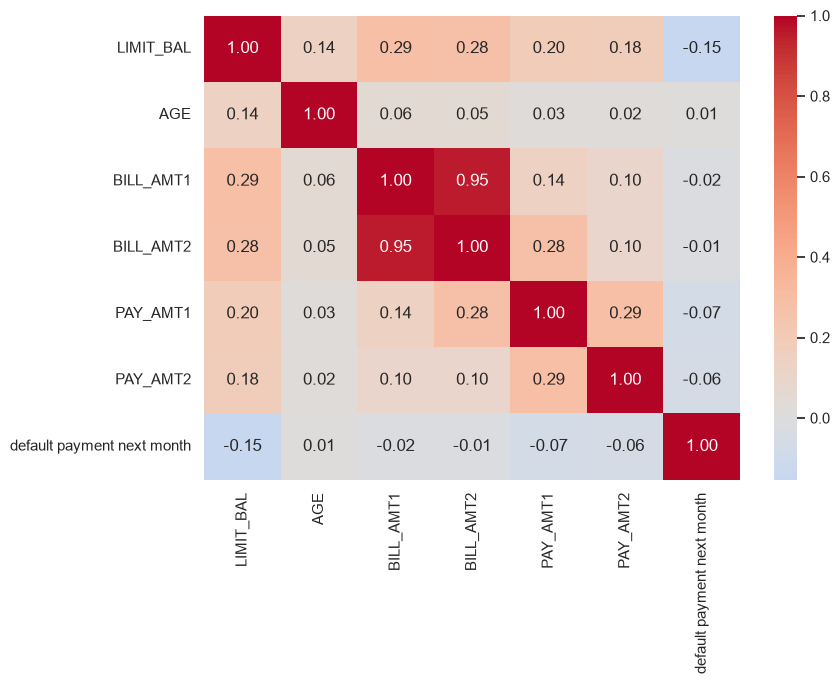

In [13]:
cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2", "PAY_AMT1", "PAY_AMT2", target]
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.tight_layout()
plt.show()

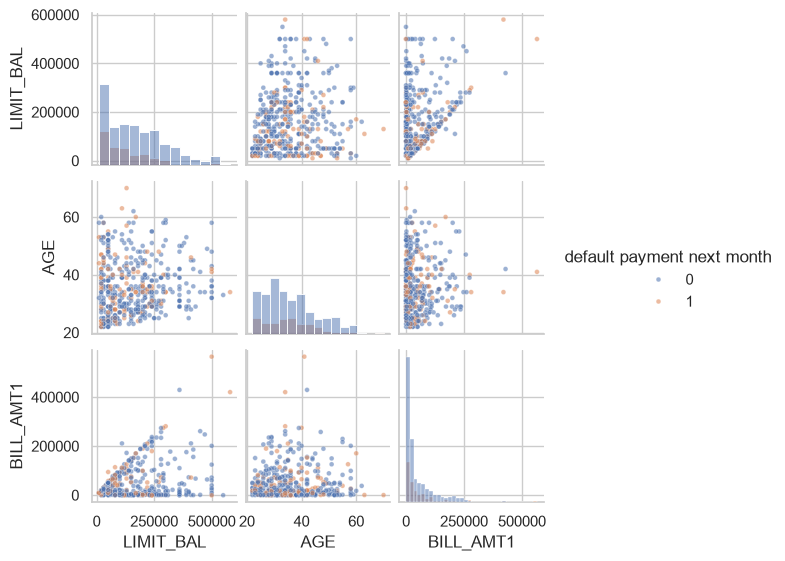

In [14]:
sample = df.sample(450, random_state=42)
sns.pairplot(sample[["LIMIT_BAL", "AGE", "BILL_AMT1", target]], hue=target,
             diag_kind="hist", plot_kws={"alpha": 0.55, "s": 12}, height=1.9)
plt.show()

Медиана `LIMIT_BAL` у класса `0` - 150 000, у `1` - 90 000. Корреляции с таргетом среди количественных признаков: `LIMIT_BAL` - -0,154, `PAY_AMT1` - -0,073, `BILL_AMT1` - -0,020, `AGE` - 0,014. Связь `BILL_AMT1` и `BILL_AMT2` высокая (около 0,951); уровни задолженности по соседним месяцам не являются независимыми. Коды статусов рассматриваются отдельно через таблицы долей по категориям.

## 8. История платежей и момент прогноза

Проверка согласованности месячных признаков и доступности сведений до прогнозируемого месяца.

In [15]:
print("PAY_0 / PAY_2: доли сочетаний статусов по строкам, %")
display((pd.crosstab(df["PAY_0"], df["PAY_2"], normalize="index") * 100).round(2))
print("BILL_AMT1 / BILL_AMT2:", round(df["BILL_AMT1"].corr(df["BILL_AMT2"]), 3))
print("PAY_AMT1 / PAY_AMT2:", round(df["PAY_AMT1"].corr(df["PAY_AMT2"]), 3))
print("Суммы счетов, отрицательные значения:")
print(pd.Series({f"BILL_AMT{i}": int(df[f"BILL_AMT{i}"].lt(0).sum()) for i in range(1, 7)}))
print("Платежи, нулевые значения:")
print(pd.Series({f"PAY_AMT{i}": int(df[f"PAY_AMT{i}"].eq(0).sum()) for i in range(1, 7)}))

PAY_0 / PAY_2: доли сочетаний статусов по строкам, %


PAY_2,-2,-1,0,1,2,3,4,5,6,7,8
PAY_0,,,,,,,,,,,
-2,92.82,7.00,0.00,0.00,0.18,0.00,0.00,0.00,0.00,0.00,0.00
-1,0.00,81.62,10.60,0.00,6.81,0.83,0.09,0.05,0.00,0.00,0.00
0,0.00,3.24,96.76,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,33.11,16.59,0.08,0.76,45.34,2.96,0.87,0.19,0.05,0.03,0.03
2,0.00,4.72,32.43,0.00,59.66,2.66,0.52,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,84.47,12.73,2.48,0.31,0.00,0.00,0.00
4,0.00,0.00,0.00,0.00,0.00,76.32,19.74,3.95,0.00,0.00,0.00
5,0.00,0.00,0.00,0.00,0.00,0.00,96.15,0.00,3.85,0.00,0.00
6,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00


BILL_AMT1 / BILL_AMT2: 0.951
PAY_AMT1 / PAY_AMT2: 0.286
Суммы счетов, отрицательные значения:
BILL_AMT1    590
BILL_AMT2    669
BILL_AMT3    655
BILL_AMT4    675
BILL_AMT5    655
BILL_AMT6    688
dtype: int64
Платежи, нулевые значения:
PAY_AMT1    5249
PAY_AMT2    5396
PAY_AMT3    5968
PAY_AMT4    6408
PAY_AMT5    6703
PAY_AMT6    7173
dtype: int64


`PAY_0` относится к сентябрю, `PAY_2` - к августу, `PAY_6` - к апрелю 2005 года; индексы `BILL_AMT*` и `PAY_AMT*` тоже соответствуют прошлым месяцам. Для прогноза следующего месяца все показатели должны быть доступны на дату расчёта.

## 9. Выводы и эталон для агента

- **Таргет:** `default payment next month`, класс `1` - невыполнение платежа.
- **Тип задачи:** бинарная классификация.
- **Дисбаланс:** 22,12% положительных наблюдений; accuracy не использовать как единственный ориентир.
- **Пропуски:** формальных `NaN` нет, но есть нераскрытые коды `EDUCATION`, `MARRIAGE` и `PAY_*`.
- **Идентификатор:** не использовать `ID` как содержательный предиктор.
- **Признаки:** различать числовые суммы и категориальные коды. Не удалять отрицательные суммы счетов без подтверждения ошибки.
- **Связь с таргетом:** проверять статусы просрочек и кредитный лимит, не приписывать корреляциям причинный смысл.
- **Момент прогноза:** согласовать дату среза истории и доступность платежных показателей.
- **Метрика:** учитывать стоимость пропущенных дефолтов и ложных предупреждений; возможны PR-AUC, recall и precision.
- **Валидация:** не объявлять случайное разбиение имитацией будущего периода без временных меток.
